In [19]:
import os
import sys
import json
import matplotlib.pyplot as plt
from IPython.display import display, Image

sys.path.insert(0, os.path.abspath("src"))

from problem import load_graph, find_classical_optimum
from qaoa_circuit import optimize_qaoa
from visualization import save_graph_visualization

print("Opti-Q: Quantum Max-Cut Project")
print("Notebook initialized successfully!")

Opti-Q: Quantum Max-Cut Project
Notebook initialized successfully!


In [20]:
from problem import load_graph, find_classical_optimum

graph = load_graph()

optimum, partition = find_classical_optimum(graph)

print("CLASSICAL MAX-CUT RESULTS")
print("Number of Nodes:", graph.number_of_nodes())
print("Number of Edges:", graph.number_of_edges())
print("Classical Optimum:", optimum)
print("Best Partition:", partition)

CLASSICAL MAX-CUT RESULTS
Number of Nodes: 6
Number of Edges: 9
Classical Optimum: 16
Best Partition: {0: 0, 1: 0, 2: 1, 3: 0, 4: 1, 5: 1}


In [21]:
import time
from qaoa_circuit import optimize_qaoa

start_time = time.time()

print("Running QAOA p=1...")
qaoa_results = optimize_qaoa(graph)

execution_time = time.time() - start_time

for key, value in qaoa_results.items():
    print(f"{key}: {value}")

approximation_ratio = qaoa_results["expected_cut"] / optimum

print("Approximation Ratio:", round(approximation_ratio, 4))
print("Execution Time:", round(execution_time, 2), "seconds")

Running QAOA p=1...
gamma: 0.11228113291223749
beta: 1.2297907044806935
expected_cut: 11.942138671875
best_cut: 16
best_bitstring: 110100
optimizer_success: True
Approximation Ratio: 0.7464
Execution Time: 0.23 seconds


Graph image saved successfully!


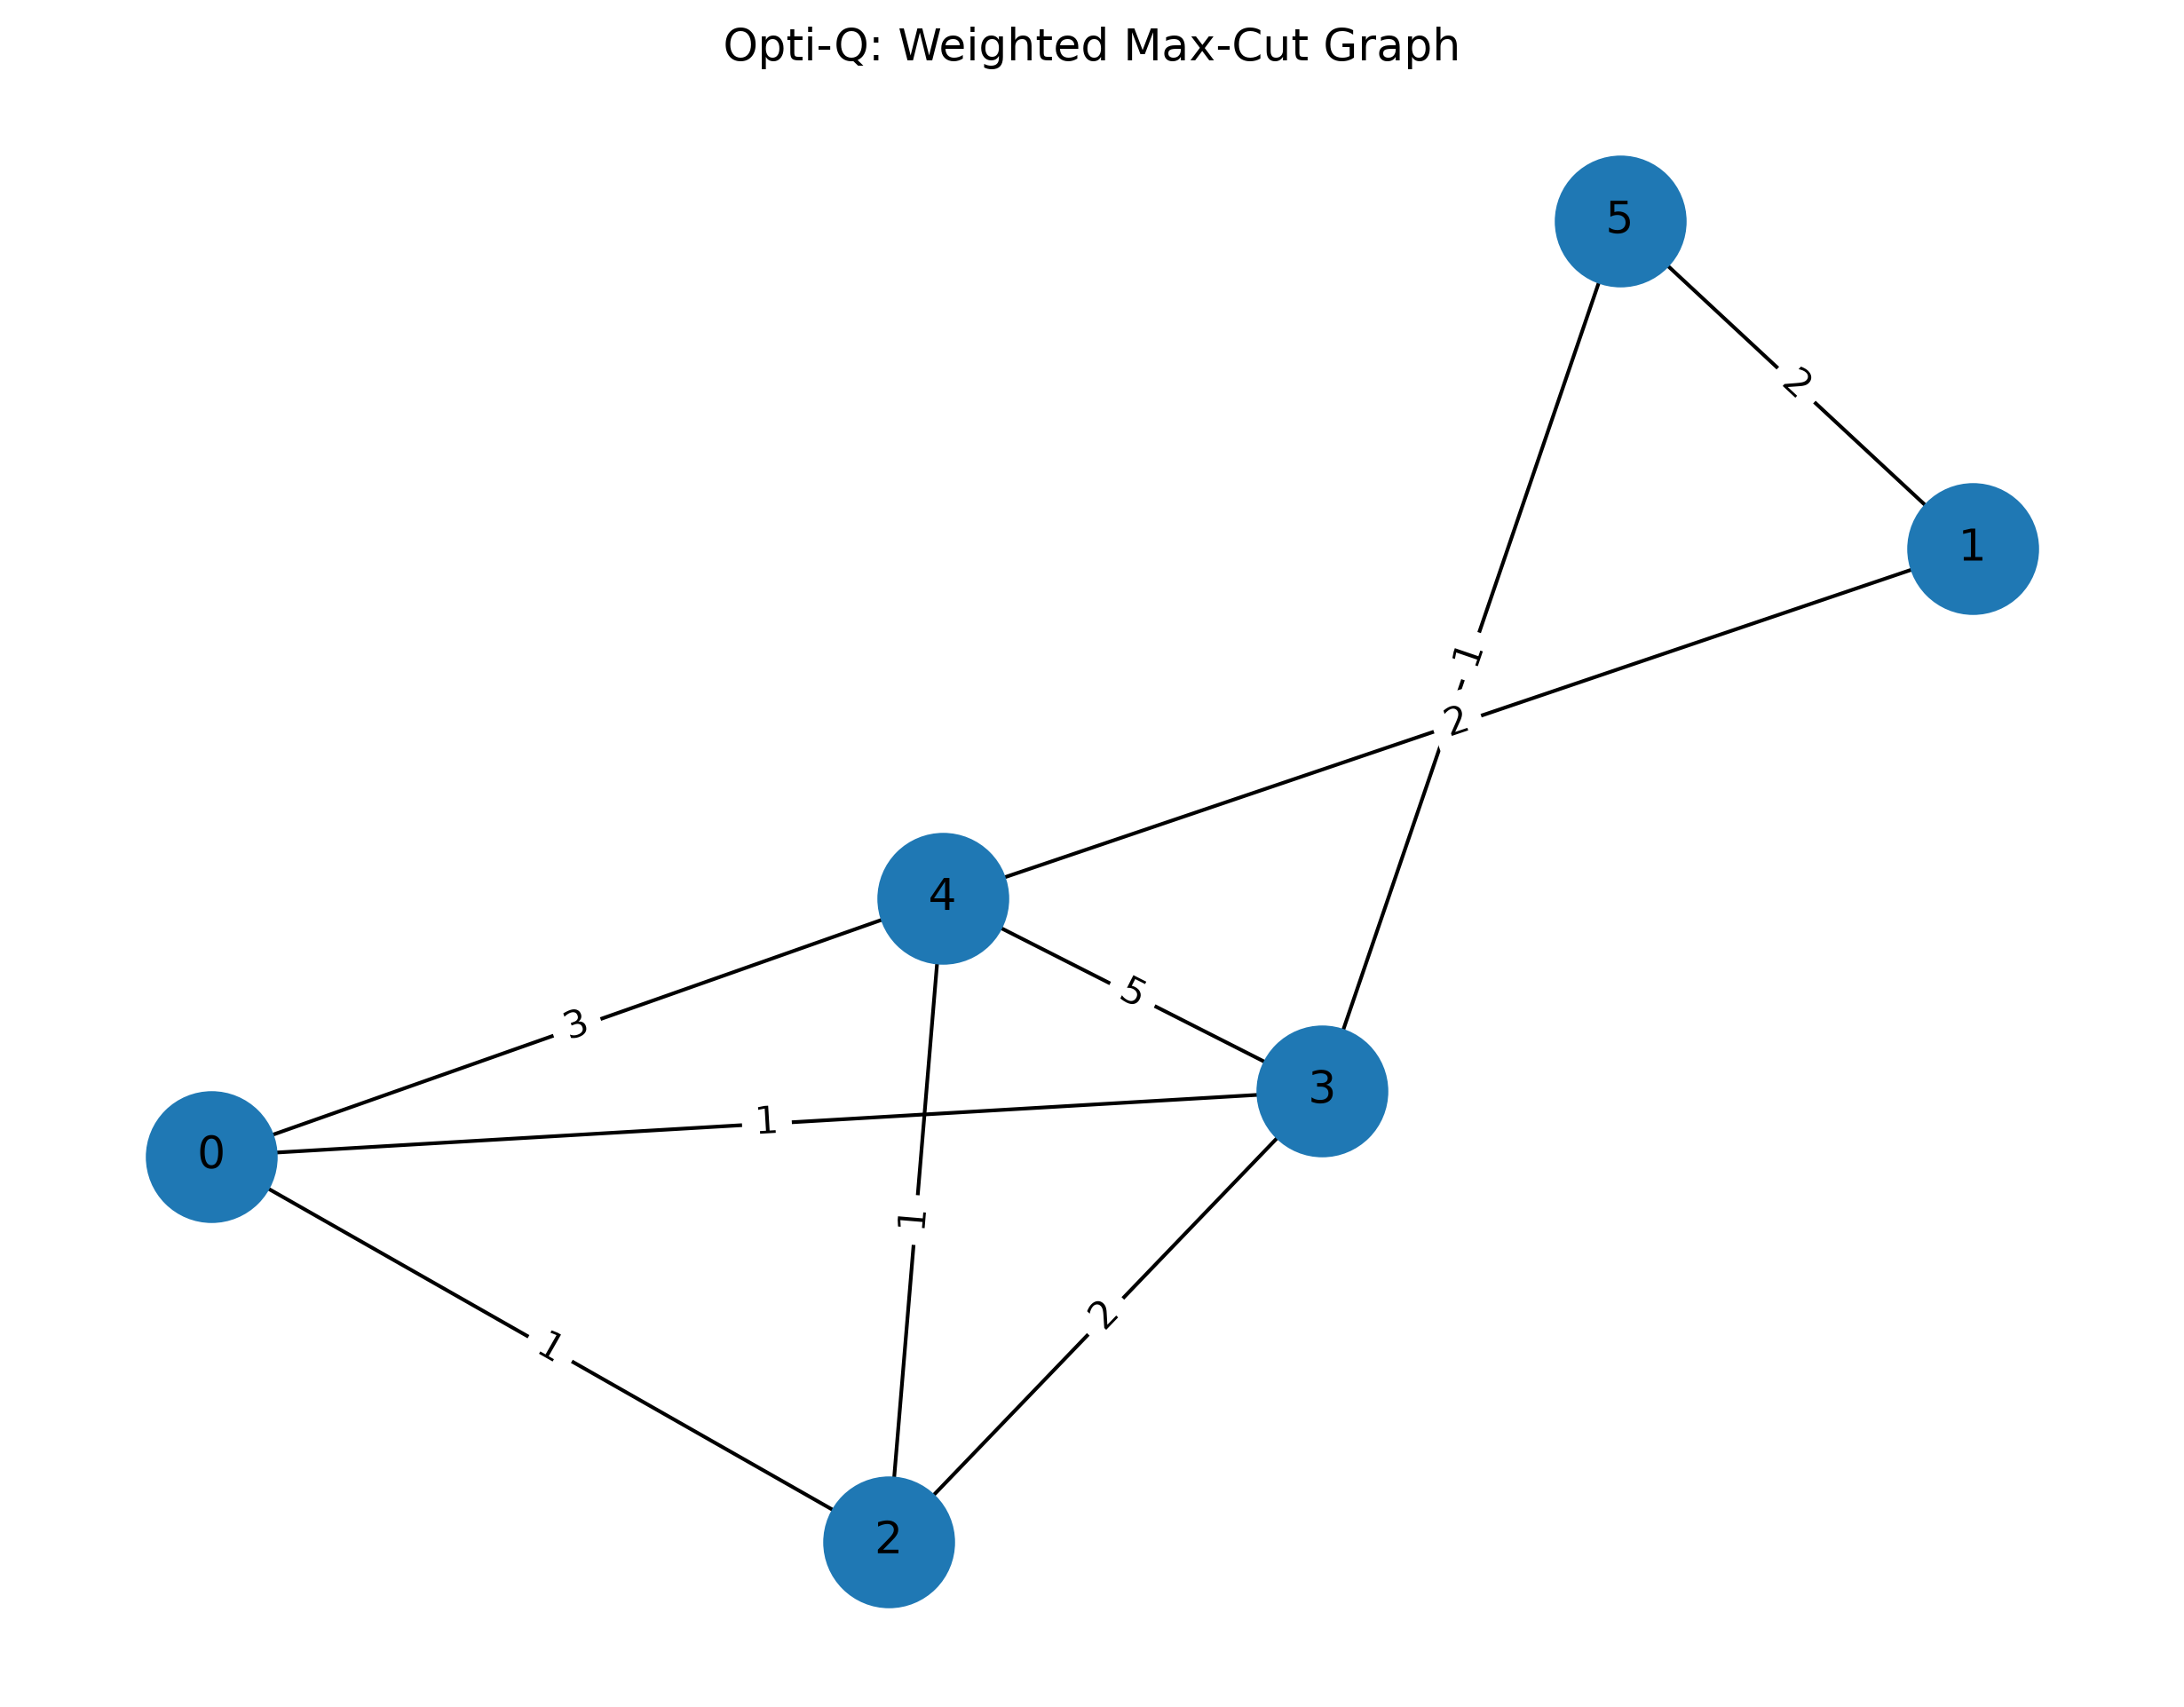

In [22]:
from visualization import save_graph_visualization
from IPython.display import Image, display

save_graph_visualization(graph)

display(Image(filename="results/figures/weighted_graph.png"))

In [23]:
import json
from IPython.display import display, Markdown

with open("results/tables/processor_comparison.json", "r") as file:
    benchmark_results = json.load(file)

display(Markdown("## Processor A vs Processor B Benchmark"))

for result in benchmark_results:
    print("\nProcessor:", result["processor"])
    for key, value in result.items():
        print(f"{key}: {value}")

## Processor A vs Processor B Benchmark


Processor: Processor A
processor: Processor A
circuit_depth: 53
swap_count: 0
two_qubit_gates: 33
topology_status: illustrative_only_not_verified_official

Processor: Processor B
processor: Processor B
circuit_depth: 40
swap_count: 0
two_qubit_gates: 27
topology_status: illustrative_only_not_verified_official


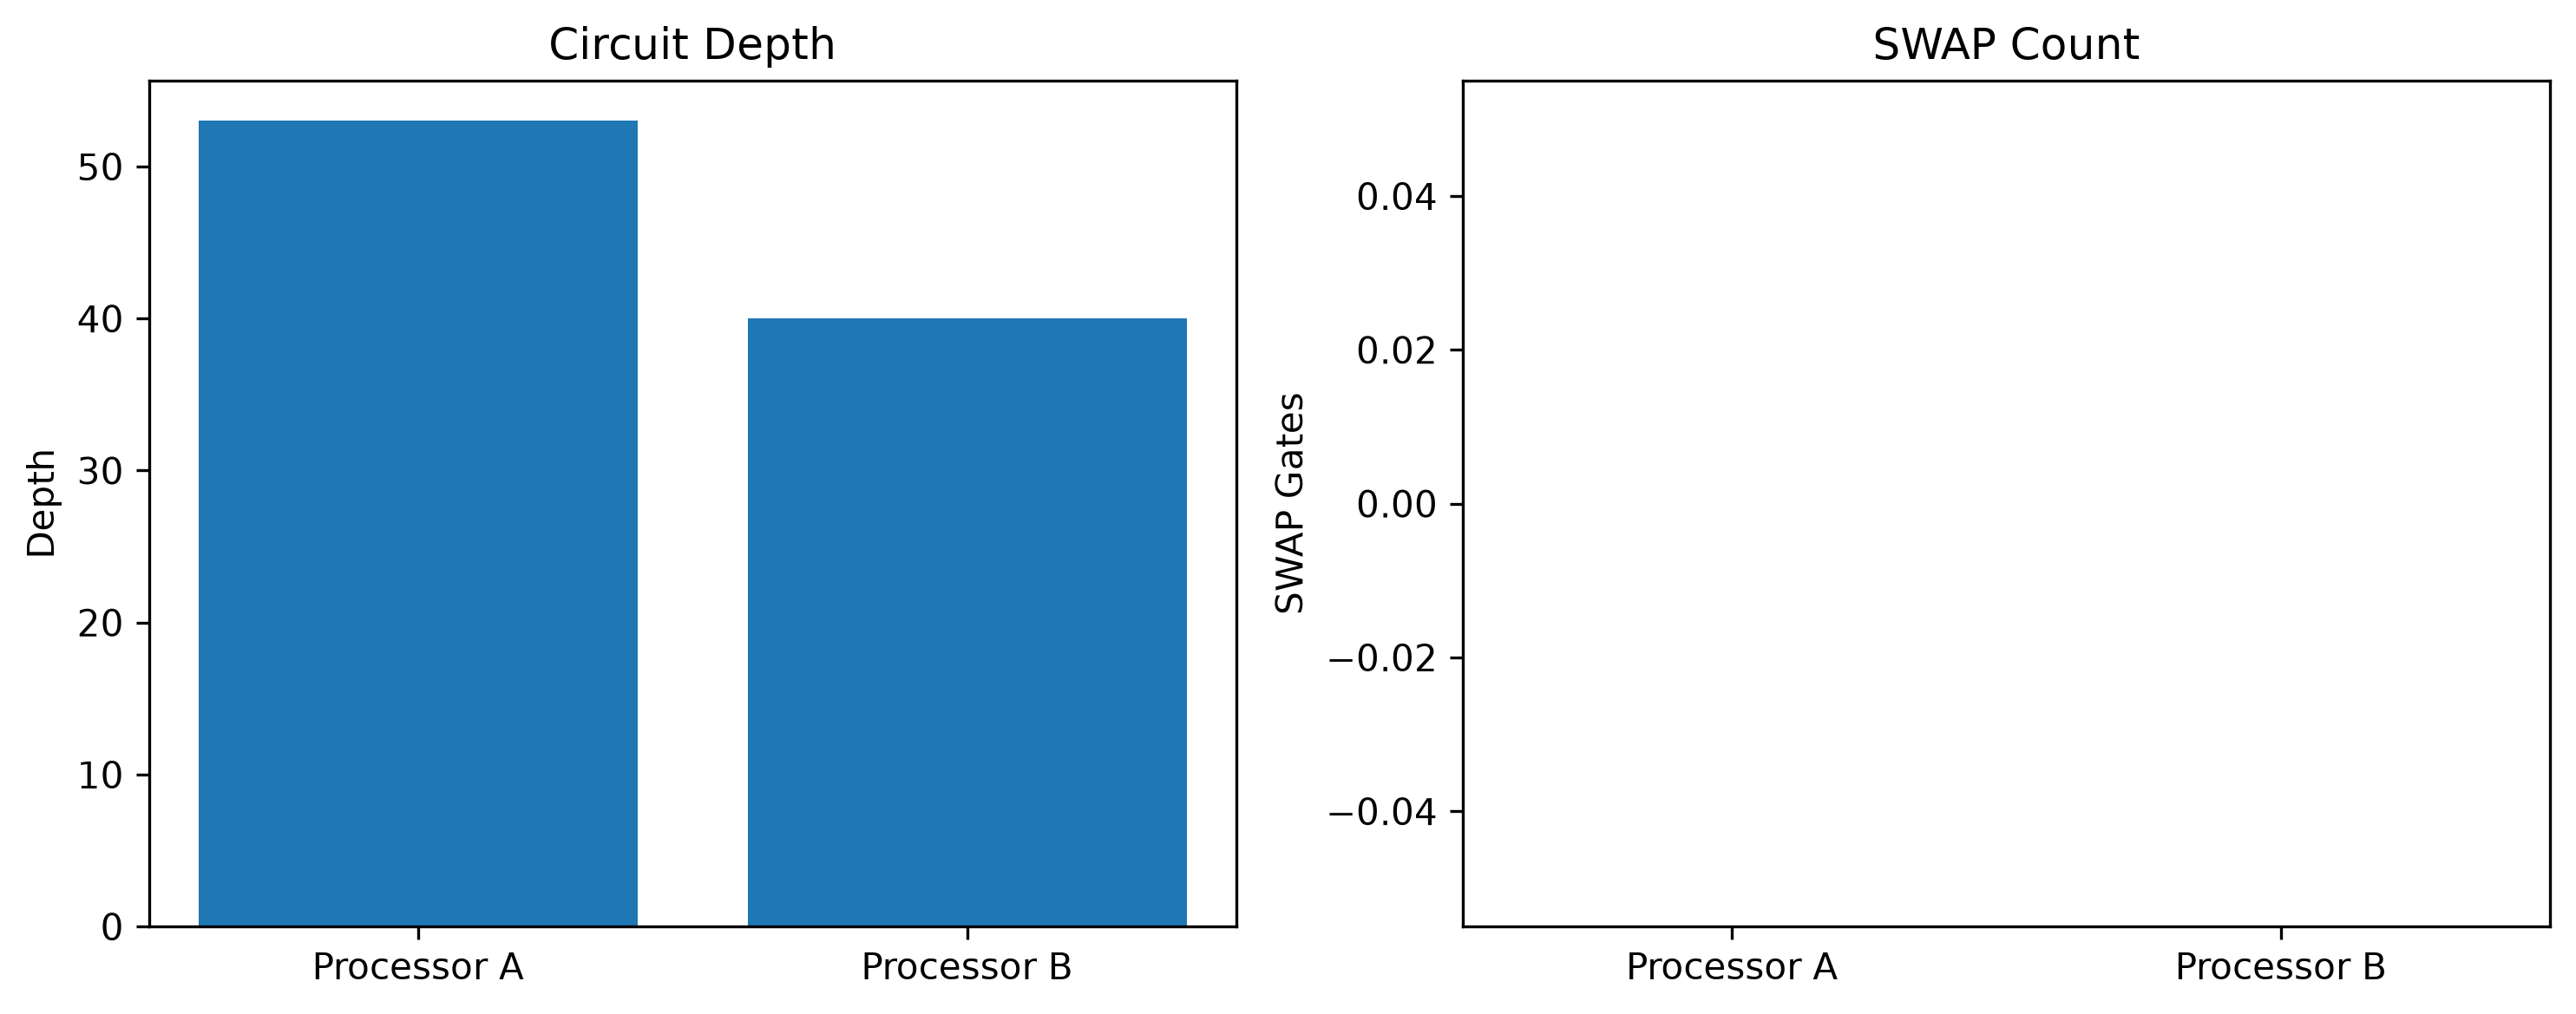

In [24]:
from IPython.display import Image, display

display(
    Image(filename="results/figures/processor_comparison.png")
)